# Step 5 — Full Three-Memory Experiment

**Project:** *When Memories Compete: How Similarity Affects Memory Retrieval in Hopfield Networks*

**Question:** for Hopfield networks storing **3** real handwritten digit images, how does the group's **mean pairwise overlap** relate to
1. **clean-pattern stability** (primary outcome): how many of the 3 stored images are exact fixed points, and
2. **noisy exact retrieval accuracy** (second main outcome): the fraction of trials at 5%, 10% and 20% corruption that end exactly at the target?

Also measured: the final overlap with the target (descriptive, never counted as retrieval) and whether different stored images converge to the **same** final state.

**Unchanged from earlier steps:** Hopfield learning and update rules (`src/hopfield.py`), the dataset, the typical-image rule, the definition of exact retrieval, the outcome categories (non-convergence checked first), and the validation checks.

**Approved sampling plan:** 180 groups in 15 overlap bins (10 groups per bin; 15 per bin in the 0.44–0.56 transition region), at most 3 uses of any image, bins filled in randomised round-robin order.

**Supporting evidence (unchanged):** step 4 (5 memories, notebook 04) and the group-size pilot (notebook 05).
Not in this notebook: the human-memory comparison and the final report.

In [34]:
import sys, json, time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.optimize import minimize
from scipy.special import expit

project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.optdigits import load_optdigits
from src.hopfield import train_hebbian, recall, is_fixed_point, corrupt, overlap   # rules unchanged

RESULTS_DIR = project_root / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_and_show(name):
    """Save the current figure to results/figures/<name>.png, then display it."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

images, labels = load_optdigits()
N = 32 * 32
patterns = 2.0 * images.reshape(len(images), N) - 1.0      # ±1, float64
M_all = patterns @ patterns.T / N                          # pairwise overlaps, float64
print("patterns:", patterns.shape, patterns.dtype)

patterns: (946, 1024) float64


In [35]:
RECOMPUTE = False

CONFIG = dict(
    SAMPLING_SEED     = 4040,
    TRIAL_SEED        = 4041,
    BOOTSTRAP_SEED    = 4042,
    SUBSET_SEED       = 4043,
    GROUP_SIZE        = 3,
    BIN_EDGES         = [0.20, 0.25, 0.30, 0.35, 0.40, 0.44, 0.46, 0.48, 0.50, 0.52, 0.54, 0.56, 0.60, 0.65, 0.70, 0.76],
    GROUPS_PER_BIN    = [10, 10, 10, 10, 10, 15, 15, 15, 15, 15, 15, 10, 10, 10, 10],
    MAX_IMAGE_USES    = 3,
    CORRUPTION_LEVELS = [0.00, 0.05, 0.10, 0.20],
    TRIALS_PER_IMAGE  = 20,
    MAX_SWEEPS        = 100,
    BOOTSTRAP_SAMPLES = 2000,
    LOGISTIC_BOOTSTRAP_SAMPLES = 1000,
    MONOTONIC_MAX_RISE = 0.15,   # largest allowed rise between consecutive bin means for "reasonably monotonic"
)
assert len(CONFIG["GROUPS_PER_BIN"]) == len(CONFIG["BIN_EDGES"]) - 1
assert sum(CONFIG["GROUPS_PER_BIN"]) == 180

LEVELS = CONFIG["CORRUPTION_LEVELS"]
K = CONFIG["GROUP_SIZE"]
edges = np.array(CONFIG["BIN_EDGES"])
n_bins = len(edges) - 1
bin_labels = [f"{edges[b]:.2f}–{edges[b+1]:.2f}" for b in range(n_bins)]
transition_bins = [b for b in range(n_bins) if edges[b] >= 0.44 and edges[b + 1] <= 0.56]
print("transition-region bins:", [bin_labels[b] for b in transition_bins])

transition-region bins: ['0.44–0.46', '0.46–0.48', '0.48–0.50', '0.50–0.52', '0.52–0.54', '0.54–0.56']


## 1. Typical-image pool (definition unchanged)

$\text{typicality}_i$ = the mean raw ±1 overlap of image $i$ with every **other** image of the same digit.
An image is **typical** if its typicality is at or above the median of its own digit, giving **476 of 946 images**.
All results apply to **groups drawn from this subset** (3 different digits per group).

In [36]:
typicality = np.zeros(len(labels))
for i in range(len(labels)):
    same = labels == labels[i]; same[i] = False
    typicality[i] = M_all[i, same].mean()
in_pool = np.zeros(len(labels), dtype=bool)
for d in range(10):
    idx_d = np.where(labels == d)[0]
    in_pool[idx_d] = typicality[idx_d] >= np.median(typicality[idx_d])
pool = np.where(in_pool)[0]
pool_by_digit = [pool[labels[pool] == d] for d in range(10)]
assert len(pool) == 476
print("typical pool:", len(pool), "images")

typical pool: 476 images


## 2. Enumerate every possible three-image group

With 3 images per group, **every** valid group can be listed: choose 3 different digits (120 ways), then one typical image of each.
That gives about 12.9 million groups. For each one we compute the mean of its 3 pairwise overlaps and its bin.

Each group is stored as one integer ID (`gid`): the groups for digit triple 1 come first, then digit triple 2, and so on.
`decode(gid)` turns an ID back into its 3 image indices.
We also count, for every bin, how often each digit appears among **all** candidate groups. This is needed later to compare digit composition.

In [37]:
digit_triples = list(combinations(range(10), 3))
block_sizes = np.array([len(pool_by_digit[a]) * len(pool_by_digit[b]) * len(pool_by_digit[c])
                        for a, b, c in digit_triples])
block_offsets = np.concatenate([[0], np.cumsum(block_sizes)])
n_total = int(block_offsets[-1])

members_per_bin = [[] for _ in range(n_bins)]        # candidate group IDs in each bin
cand_digit_counts = np.zeros((n_bins, 10))            # digit appearances among all candidates in each bin
all_hist_edges = np.arange(0.15, 0.80, 0.01)
all_hist = np.zeros(len(all_hist_edges) - 1)          # fine histogram of ALL groups (for plotting)
n_outside = 0

for t, (a, b, c) in enumerate(digit_triples):
    A, B, C = pool_by_digit[a], pool_by_digit[b], pool_by_digit[c]
    m = (M_all[np.ix_(A, B)][:, :, None] + M_all[np.ix_(A, C)][:, None, :] + M_all[np.ix_(B, C)][None, :, :]) / 3
    m = m.ravel()                                     # local index = np.ravel_multi_index((ia, ib, ic), shape)
    all_hist += np.histogram(m, all_hist_edges)[0]
    bins = np.digitize(m, edges) - 1
    inside = (m >= edges[0]) & (m < edges[-1])
    n_outside += int((~inside).sum())
    for bb in np.unique(bins[inside]):
        local = np.where(inside & (bins == bb))[0]
        members_per_bin[bb].append((block_offsets[t] + local).astype(np.int64))
        cand_digit_counts[bb, [a, b, c]] += len(local)

members_per_bin = [np.concatenate(x) if x else np.array([], dtype=np.int64) for x in members_per_bin]
cand_per_bin = np.array([len(x) for x in members_per_bin])

def decode(gid):
    """Group ID -> array of 3 image indices."""
    t = int(np.searchsorted(block_offsets, gid, side="right") - 1)
    a, b, c = digit_triples[t]
    shape = (len(pool_by_digit[a]), len(pool_by_digit[b]), len(pool_by_digit[c]))
    ia, ib, ic = np.unravel_index(int(gid - block_offsets[t]), shape)
    return np.array([pool_by_digit[a][ia], pool_by_digit[b][ib], pool_by_digit[c][ic]])

def mean_pairwise_overlap(idx):
    return float(np.mean([M_all[i, j] for i, j in combinations(idx, 2)]))

print(f"all possible 3-image groups: {n_total:,}  (outside the bin range: {n_outside:,})")
pd.DataFrame(dict(bin=bin_labels, candidates=cand_per_bin, target=CONFIG["GROUPS_PER_BIN"]))

all possible 3-image groups: 12,906,062  (outside the bin range: 1)


,bin,candidates,target
0,0.20–0.25,1151,10
1,0.25–0.30,46301,10
2,0.30–0.35,406559,10
3,0.35–0.40,1693526,10
4,0.40–0.44,2605857,10
5,0.44–0.46,1689856,15
6,0.46–0.48,1577421,15
7,0.48–0.50,1431977,15
8,0.50–0.52,1254166,15
9,0.52–0.54,874872,15


## 3. Sampling: randomised round-robin with an image-reuse cap

The cap (**each image in at most 3 groups**) means early draws use up images that later draws can't use.
If the bins were filled one after another, the last bins would face the tightest constraints. To avoid favouring any bin:

1. With the seeded generator, shuffle each bin's candidate list once.
2. Fill the bins in **rounds**. In each round, visit the bins that still need groups in a **freshly shuffled order**, and each takes **one** group.
3. A bin takes the next candidate in its shuffled list whose 3 images have each been used fewer than 3 times. Candidates that would break the cap are skipped.
4. If a bin runs out of candidates before reaching its target, that is recorded as a **shortfall**, and the rule is never relaxed.

The result is reproducible: the same seed always produces the same 180 groups.

In [38]:
samp_rng = np.random.default_rng(CONFIG["SAMPLING_SEED"])
shuffled = [samp_rng.permutation(members_per_bin[b]) for b in range(n_bins)]
pointer = np.zeros(n_bins, dtype=int)
target = np.array(CONFIG["GROUPS_PER_BIN"])
got = np.zeros(n_bins, dtype=int)
exhausted = np.zeros(n_bins, dtype=bool)
uses = np.zeros(len(labels), dtype=int)
sampled = []          # list of (bin, gid, round)
skipped_for_cap = np.zeros(n_bins, dtype=int)

rnd = 0
while True:
    active = [b for b in range(n_bins) if got[b] < target[b] and not exhausted[b]]
    if not active:
        break
    for b in samp_rng.permutation(active):
        while pointer[b] < len(shuffled[b]):
            gid = shuffled[b][pointer[b]]; pointer[b] += 1
            idx = decode(gid)
            if np.all(uses[idx] < CONFIG["MAX_IMAGE_USES"]):
                uses[idx] += 1; got[b] += 1
                sampled.append((b, int(gid), rnd))
                break
            skipped_for_cap[b] += 1
        else:
            exhausted[b] = True
    rnd += 1

# Group IDs in order of bin, then draw order
sampled.sort(key=lambda x: (x[0], x[2]))
groups = []
for g_id, (b, gid, r) in enumerate(sampled):
    idx = decode(gid)
    m = mean_pairwise_overlap(idx)
    assert edges[b] <= m < edges[b + 1]
    groups.append(dict(group_id=g_id, bin=b, idx=idx, mean_overlap=m, digits=labels[idx], fill_round=r))

sampling_report = pd.DataFrame(dict(bin=bin_labels, candidates=cand_per_bin, target=target, sampled=got,
                                    shortfall=target - got, skipped_for_cap=skipped_for_cap))
print(f"sampled {len(groups)} of {target.sum()} groups in {rnd} rounds; total shortfall = {(target - got).sum()}")
sampling_report

sampled 180 of 180 groups in 15 rounds; total shortfall = 0


,bin,candidates,target,sampled,shortfall,skipped_for_cap
0,0.20–0.25,1151,10,10,0,23
1,0.25–0.30,46301,10,10,0,11
2,0.30–0.35,406559,10,10,0,1
3,0.35–0.40,1693526,10,10,0,2
4,0.40–0.44,2605857,10,10,0,0
5,0.44–0.46,1689856,15,15,0,4
6,0.46–0.48,1577421,15,15,0,3
7,0.48–0.50,1431977,15,15,0,2
8,0.50–0.52,1254166,15,15,0,1
9,0.52–0.54,874872,15,15,0,1


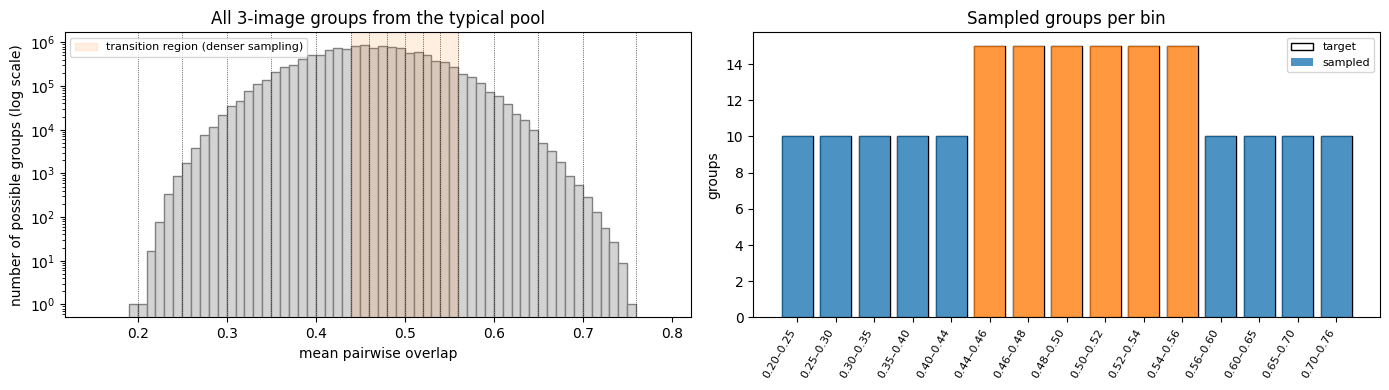

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
centers = (all_hist_edges[:-1] + all_hist_edges[1:]) / 2
axes[0].bar(centers, all_hist, width=0.01, color="lightgray", edgecolor="gray")
axes[0].set_yscale("log")
for e in edges:
    axes[0].axvline(e, color="k", lw=0.5, ls=":")
axes[0].axvspan(0.44, 0.56, color="tab:orange", alpha=0.12, label="transition region (denser sampling)")
axes[0].set_xlabel("mean pairwise overlap"); axes[0].set_ylabel("number of possible groups (log scale)")
axes[0].set_title("All 3-image groups from the typical pool"); axes[0].legend(fontsize=8)

x = np.arange(n_bins)
axes[1].bar(x, target, color="none", edgecolor="k", label="target")
axes[1].bar(x, got, color=["tab:orange" if b in transition_bins else "tab:blue" for b in range(n_bins)], alpha=0.8, label="sampled")
axes[1].set_xticks(x); axes[1].set_xticklabels(bin_labels, rotation=60, ha="right", fontsize=8)
axes[1].set_ylabel("groups"); axes[1].set_title("Sampled groups per bin"); axes[1].legend(fontsize=8)
plt.tight_layout()
save_and_show("step5_sampling")

### Image reuse and digit composition

**Reuse:** how many groups each image appears in (the cap is 3).
**Composition:** for each bin, compare how often each digit appears in the **sampled** groups with how often it appears among **all candidate** groups in that bin.
The summary number per bin is the **total variation distance** (TVD): half the sum of absolute differences between the two digit distributions. It runs from 0 (identical) to 1 (no overlap).
Large differences would mean the reuse cap or chance tilted the sample toward particular digits.

In [40]:
used = uses[pool]
print(f"image slots: {3 * len(groups)}, distinct images used: {(used > 0).sum()} of {len(pool)}")
print("images by number of uses:", {u: int((used == u).sum()) for u in range(CONFIG['MAX_IMAGE_USES'] + 1)})
assert uses.max() <= CONFIG["MAX_IMAGE_USES"]

samp_digit_counts = np.zeros((n_bins, 10))
for g in groups:
    samp_digit_counts[g["bin"], g["digits"]] += 1
samp_dist = samp_digit_counts / np.maximum(samp_digit_counts.sum(1, keepdims=True), 1)
cand_dist = cand_digit_counts / np.maximum(cand_digit_counts.sum(1, keepdims=True), 1)
tvd = 0.5 * np.abs(samp_dist - cand_dist).sum(axis=1)
sampling_report["digit_TVD_vs_candidates"] = tvd.round(3)

# What TVD would we expect from chance alone? Draw the same number of groups from each bin WITHOUT the cap.
chance_rng = np.random.default_rng(CONFIG["SAMPLING_SEED"] + 100)
chance_tvd = np.zeros((200, n_bins))
for r in range(200):
    for b in range(n_bins):
        if got[b] == 0:
            continue
        cnt = np.zeros(10)
        for gid in chance_rng.choice(members_per_bin[b], size=got[b], replace=False):
            cnt[labels[decode(gid)]] += 1
        chance_tvd[r, b] = 0.5 * np.abs(cnt / cnt.sum() - cand_dist[b]).sum()
sampling_report["chance_TVD_95pct"] = np.percentile(chance_tvd, 95, axis=0).round(3)
sampling_report["TVD_above_chance"] = sampling_report.digit_TVD_vs_candidates > sampling_report.chance_TVD_95pct
sampling_report

image slots: 540, distinct images used: 313 of 476
images by number of uses: {0: 163, 1: 155, 2: 89, 3: 69}


,bin,candidates,target,sampled,shortfall,skipped_for_cap,digit_TVD_vs_candidates,chance_TVD_95pct,TVD_above_chance
0,0.20–0.25,1151,10,10,0,23,0.082,0.139,False
1,0.25–0.30,46301,10,10,0,11,0.147,0.196,False
2,0.30–0.35,406559,10,10,0,1,0.189,0.253,False
3,0.35–0.40,1693526,10,10,0,2,0.146,0.273,False
4,0.40–0.44,2605857,10,10,0,0,0.240,0.282,False
5,0.44–0.46,1689856,15,15,0,4,0.134,0.228,False
6,0.46–0.48,1577421,15,15,0,3,0.137,0.223,False
7,0.48–0.50,1431977,15,15,0,2,0.107,0.232,False
8,0.50–0.52,1254166,15,15,0,1,0.163,0.236,False
9,0.52–0.54,874872,15,15,0,1,0.155,0.225,False


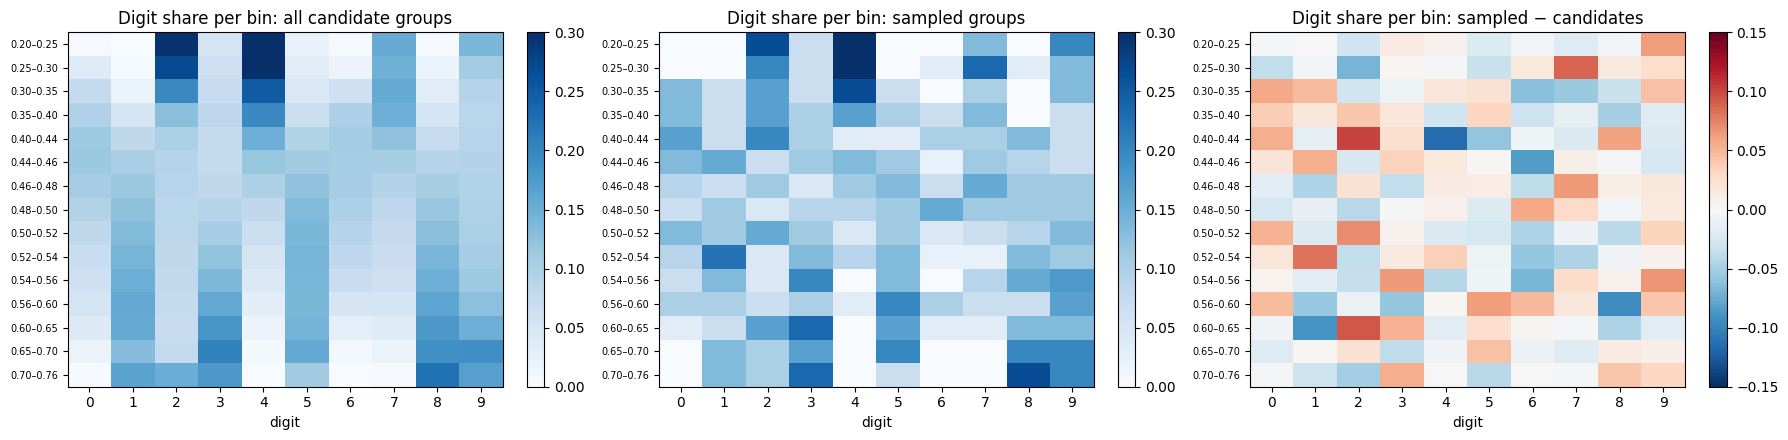

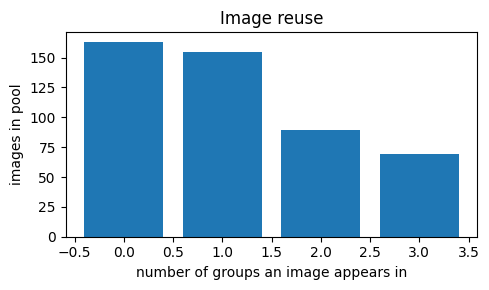

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1, 1, 1]})
for ax, mat, title, cmap, v in [(axes[0], cand_dist, "all candidate groups", "Blues", (0, 0.3)),
                                (axes[1], samp_dist, "sampled groups", "Blues", (0, 0.3)),
                                (axes[2], samp_dist - cand_dist, "sampled − candidates", "RdBu_r", (-0.15, 0.15))]:
    im = ax.imshow(mat, cmap=cmap, vmin=v[0], vmax=v[1], aspect="auto")
    ax.set_xticks(range(10)); ax.set_yticks(range(n_bins)); ax.set_yticklabels(bin_labels, fontsize=7)
    ax.set_xlabel("digit"); ax.set_title(f"Digit share per bin: {title}")
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
save_and_show("step5_digit_composition")

plt.figure(figsize=(5, 3))
plt.bar(range(CONFIG["MAX_IMAGE_USES"] + 1), [(used == u).sum() for u in range(CONFIG["MAX_IMAGE_USES"] + 1)])
plt.xlabel("number of groups an image appears in"); plt.ylabel("images in pool")
plt.title("Image reuse")
plt.tight_layout()
save_and_show("step5_image_reuse")

## 4. Protocol (unchanged definitions)

For each group: store its 3 images (`train_hebbian`). For corruption levels 0%, 5%, 10% and 20%, each image and 20 trials: flip exactly round(level × 1024) random pixels, run `recall`, then classify.

Outcome categories, checked **in this order**, are mutually exclusive:
`not_converged` (checked first) → `correct` (exact target) → `wrong_memory` (exactly another stored image) → `mirror` (exactly the inverse of a stored image) → `other_attractor` (anything else, e.g. a blend; never counted as a stored memory).

**Primary outcome, clean stability:** the number of stored images that are exact fixed points (`is_fixed_point == 1.0`) / 3.
**Second main outcome, noisy exact retrieval accuracy:** the fraction of a group's 60 trials (3 images × 20) at 5%, 10% or 20% that end exactly at the target.

**Final states** are saved compactly: each 1,024-pixel ±1 state is packed into **128 bytes** (`np.packbits`, 1 bit per neuron). They are stored in `results/step5_final_states.npy` with row number = `trial_id`, the same ID used in the trial CSV.

**Seeds:** each group gets its own stream, `SeedSequence(TRIAL_SEED).spawn(n_groups)[group_id]`, so any group can be re-run on its own.

In [42]:
CATEGORIES = ["correct", "wrong_memory", "mirror", "other_attractor", "not_converged"]

def classify(res, target_pos, stored):
    """Identical to notebooks 04 and 05."""
    if not res["converged"]:
        return "not_converged"
    s = res["state"]
    if np.array_equal(s, stored[target_pos]):
        return "correct"
    for k in range(len(stored)):
        if k != target_pos and np.array_equal(s, stored[k]):
            return "wrong_memory"
    for k in range(len(stored)):
        if np.array_equal(s, -stored[k]):
            return "mirror"
    return "other_attractor"

def pack_state(s):
    """±1 vector of 1024 -> 128 uint8 bytes (bit = 1 for +1)."""
    return np.packbits(s > 0)

def unpack_state(b):
    """128 bytes -> ±1 float64 vector of 1024."""
    return np.unpackbits(b)[:N].astype(np.float64) * 2 - 1

def run_group(g, rng):
    idx = g["idx"]
    stored = patterns[idx]
    for a, b in combinations(range(K), 2):
        assert not np.array_equal(stored[a], stored[b]) and not np.array_equal(stored[a], -stored[b])
    W = train_hebbian(stored)
    assert np.array_equal(W, W.T) and np.all(np.diag(W) == 0)          # validation: symmetric, zero diagonal
    stable = np.array([is_fixed_point(W, p) == 1.0 for p in stored])
    rows, states = [], []
    for level in LEVELS:
        for pos in range(K):
            for t in range(CONFIG["TRIALS_PER_IMAGE"]):
                res = recall(W, corrupt(stored[pos], level, rng), rng, max_sweeps=CONFIG["MAX_SWEEPS"])
                rows.append(dict(group_id=g["group_id"], image_pos=pos, image_index=int(idx[pos]),
                                 digit=int(labels[idx[pos]]), corruption=level, trial=t,
                                 outcome=classify(res, pos, stored),
                                 final_overlap_target=overlap(res["state"], stored[pos]),
                                 sweeps=res["sweeps"], converged=res["converged"]))
                states.append(pack_state(res["state"]))
    return rows, states, stable

In [43]:
TRIALS_CSV = RESULTS_DIR / "step5_trials.csv"
GROUPS_CSV = RESULTS_DIR / "step5_groups.csv"
STATES_NPY = RESULTS_DIR / "step5_final_states.npy"
SAMPLING_CSV = RESULTS_DIR / "step5_sampling_report.csv"
CONFIG_JSON = RESULTS_DIR / "step5_config.json"

def saved_config_matches():
    return CONFIG_JSON.exists() and json.loads(CONFIG_JSON.read_text()) == json.loads(json.dumps(CONFIG))

if RECOMPUTE or not all(p.exists() for p in [TRIALS_CSV, GROUPS_CSV, STATES_NPY]) or not saved_config_matches():
    t0 = time.time()
    seeds = np.random.SeedSequence(CONFIG["TRIAL_SEED"]).spawn(len(groups))
    all_rows, all_states, ginfo = [], [], []
    for g, ss in zip(groups, seeds):
        rows, states, stable = run_group(g, np.random.default_rng(ss))
        all_rows += rows; all_states += states
        ginfo.append(dict(group_id=g["group_id"], bin=g["bin"], bin_label=bin_labels[g["bin"]],
                          mean_overlap=g["mean_overlap"], fill_round=g["fill_round"],
                          images=" ".join(map(str, g["idx"])), digits=" ".join(map(str, g["digits"])),
                          n_stable=int(stable.sum())))
    trials = pd.DataFrame(all_rows)
    trials.insert(0, "trial_id", np.arange(len(trials)))
    final_states = np.array(all_states, dtype=np.uint8)            # shape (n_trials, 128)
    ginfo = pd.DataFrame(ginfo)
    trials.to_csv(TRIALS_CSV, index=False); ginfo.to_csv(GROUPS_CSV, index=False)
    np.save(STATES_NPY, final_states)
    sampling_report.to_csv(SAMPLING_CSV, index=False)
    CONFIG_JSON.write_text(json.dumps(CONFIG, indent=2))
    print(f"experiment ran in {time.time() - t0:.0f} s; saved to {RESULTS_DIR}")
else:
    trials, ginfo = pd.read_csv(TRIALS_CSV), pd.read_csv(GROUPS_CSV)
    final_states = np.load(STATES_NPY)
    print("loaded saved results")

assert np.allclose(ginfo.mean_overlap.values, [g["mean_overlap"] for g in groups]), "saved groups differ from sampled groups"
print(f"{len(ginfo)} groups, {len(trials):,} trials, final_states {final_states.shape} {final_states.dtype} "
      f"({final_states.nbytes / 1e6:.1f} MB)")

loaded saved results
180 groups, 43,200 trials, final_states (43200, 128) uint8 (5.5 MB)


### Validation checks
Same as step 4, plus checks on the saved binary states.

In [44]:
per_group = K * len(LEVELS) * CONFIG["TRIALS_PER_IMAGE"]
assert len(trials) == len(ginfo) * per_group
assert np.array_equal(trials.trial_id.values, np.arange(len(trials)))
assert final_states.shape == (len(trials), N // 8)
assert set(trials.outcome) <= set(CATEGORIES)

# Packing is lossless
x = patterns[0]
assert np.array_equal(unpack_state(pack_state(x)), x)

# Saved states agree with the recorded outcome and final overlap.
# Check a seeded random sample of 2,000 trials, plus every 'correct' trial.
chk_rng = np.random.default_rng(0)
check_ids = np.union1d(chk_rng.choice(len(trials), 2000, replace=False), trials.index[trials.outcome == "correct"])
gidx = {r.group_id: np.array(list(map(int, r.images.split()))) for r in ginfo.itertuples()}
for tid in check_ids:
    r = trials.iloc[tid]
    s = unpack_state(final_states[tid])
    target_img = patterns[gidx[r.group_id][r.image_pos]]
    assert np.isclose(overlap(s, target_img), r.final_overlap_target)
    assert (r.outcome == "correct") == np.array_equal(s, target_img)

# 0% accuracy must equal clean stability (fixed point <=> exact clean retrieval)
acc0 = trials[trials.corruption == 0].groupby("group_id").outcome.apply(lambda o: (o == "correct").mean())
assert np.allclose(acc0.values, ginfo.set_index("group_id").loc[acc0.index, "n_stable"] / K)

assert np.all(trials.loc[trials.outcome == "correct", "final_overlap_target"] == 1.0)
print("non-converged trials:", int((trials.outcome == "not_converged").sum()),
      "| max sweeps used:", int(trials.sweeps.max()), "of", CONFIG["MAX_SWEEPS"])
print(f"checked {len(check_ids):,} saved states against recorded outcomes")
print("All validation checks passed.")

non-converged trials: 0 | max sweeps used: 3 of 100
checked 21,662 saved states against recorded outcomes
All validation checks passed.


## 5. Group-level summary

Everything below uses **one row per group** (n = 180). Trials are only averaged *within* a group.

**Attractor sharing** (per group and corruption level, from the saved exact states):
- `n_distinct_final`: the number of different final states reached
- `frac_pairs_shared`: of the 3 image pairs, the fraction where at least one trial from each image ended in the **identical** state
- `all_merged`: every trial from every image ended in one single, common state

In [45]:
def attractor_sharing(tids, pos):
    keys = [final_states[t].tobytes() for t in tids]
    finals = {p: set() for p in range(K)}
    for k, p in zip(keys, pos):
        finals[p].add(k)
    pairs = list(combinations(range(K), 2))
    shared = [len(finals[a] & finals[b]) > 0 for a, b in pairs]
    allk = set(keys)
    return len(allk), float(np.mean(shared)), len(allk) == 1

gs = ginfo.set_index("group_id").copy()
gs["stable_frac"] = gs.n_stable / K                         # PRIMARY outcome
for level in LEVELS:
    c = int(level * 100)
    sub = trials[trials.corruption == level]
    grp = sub.groupby("group_id")
    gs[f"acc_{c}"] = grp.outcome.apply(lambda o: (o == "correct").mean())
    gs[f"final_overlap_{c}"] = grp.final_overlap_target.mean()
    for cat in CATEGORIES:
        gs[f"{cat}_{c}"] = grp.outcome.apply(lambda o, cat=cat: (o == cat).mean())
    share = {gid: attractor_sharing(t.trial_id.values, t.image_pos.values) for gid, t in grp}
    gs[f"n_distinct_{c}"] = [share[g][0] for g in gs.index]
    gs[f"pairs_shared_{c}"] = [share[g][1] for g in gs.index]
    gs[f"all_merged_{c}"] = [share[g][2] for g in gs.index]
    assert np.allclose(sum(gs[f"{cat}_{c}"] for cat in CATEGORIES), 1.0)   # categories exhaustive

gs["noisy_acc_mean"] = gs[["acc_5", "acc_10", "acc_20"]].mean(axis=1)
gs.reset_index().to_csv(RESULTS_DIR / "step5_group_summary.csv", index=False)
gs[["bin_label", "mean_overlap", "digits", "stable_frac", "acc_5", "acc_10", "acc_20", "final_overlap_10", "pairs_shared_10"]].head()

,bin_label,mean_overlap,digits,stable_frac,acc_5,acc_10,acc_20,final_overlap_10,pairs_shared_10
group_id,,,,,,,,,
0,0.20–0.25,0.246094,2 3 4,1.0,1.0,1.0,1.0,1.0,0.0
1,0.20–0.25,0.246094,2 3 4,1.0,1.0,1.0,1.0,1.0,0.0
2,0.20–0.25,0.242188,2 4 9,1.0,1.0,1.0,1.0,1.0,0.0
3,0.20–0.25,0.246094,2 4 9,1.0,1.0,1.0,1.0,1.0,0.0
4,0.20–0.25,0.243490,2 4 9,1.0,1.0,1.0,1.0,1.0,0.0


In [46]:
boot_rng = np.random.default_rng(CONFIG["BOOTSTRAP_SEED"])
B = CONFIG["BOOTSTRAP_SAMPLES"]

def bin_means_ci(df, col):
    """Mean of col per bin with a bootstrap 95% CI (resampling groups within the bin)."""
    out = []
    for b in range(n_bins):
        v = df.loc[df.bin == b, col].values
        if len(v) == 0:
            out.append((np.nan, np.nan, np.nan)); continue
        boots = boot_rng.choice(v, size=(B, len(v)), replace=True).mean(axis=1)
        out.append((v.mean(), *np.percentile(boots, [2.5, 97.5])))
    return np.array(out)

def spearman_ci(x, y):
    x, y = np.asarray(x), np.asarray(y)
    if np.all(y == y[0]):
        return np.nan, np.nan, np.nan
    rho = spearmanr(x, y).statistic
    boots = []
    for _ in range(B):
        i = boot_rng.integers(0, len(x), len(x))
        if np.all(y[i] == y[i][0]):
            continue
        boots.append(spearmanr(x[i], y[i]).statistic)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return rho, lo, hi

bin_mid = np.array([gs.loc[gs.bin == b, "mean_overlap"].mean() if (gs.bin == b).any() else np.nan for b in range(n_bins)])

## 6. Primary outcome: clean-pattern stability

Each dot is one group: the fraction of its 3 images that are exact fixed points (0, ⅓, ⅔ or 1), with a little vertical jitter so overlapping dots are visible.
Black: the bin mean with a bootstrap 95% CI.
Orange: the 12 size-3 pilot groups from notebook 05, shown for reference and **not included** in any statistic.

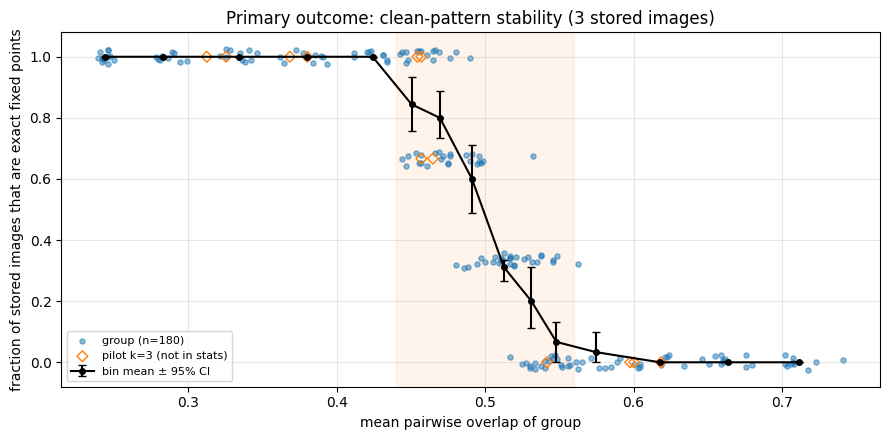

,bin,n,stable_mean,ci_low,ci_high
0,0.20–0.25,10,1.000,1.000,1.000
1,0.25–0.30,10,1.000,1.000,1.000
2,0.30–0.35,10,1.000,1.000,1.000
3,0.35–0.40,10,1.000,1.000,1.000
4,0.40–0.44,10,1.000,1.000,1.000
5,0.44–0.46,15,0.844,0.756,0.933
6,0.46–0.48,15,0.800,0.733,0.889
7,0.48–0.50,15,0.600,0.489,0.711
8,0.50–0.52,15,0.311,0.267,0.333
9,0.52–0.54,15,0.200,0.111,0.311


In [47]:
pilot = pd.read_csv(RESULTS_DIR / "pilot_groupsize_groups.csv")
pilot3 = pilot[pilot["size"] == 3].assign(stable_frac=lambda d: d.n_stable / 3)

jit = np.random.default_rng(1).uniform(-0.025, 0.025, len(gs))
bm = bin_means_ci(gs, "stable_frac")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(0.44, 0.56, color="tab:orange", alpha=0.08)
ax.scatter(gs.mean_overlap, gs.stable_frac + jit, s=14, alpha=0.5, color="tab:blue", label="group (n=180)")
ax.errorbar(bin_mid, bm[:, 0], yerr=[bm[:, 0] - bm[:, 1], bm[:, 2] - bm[:, 0]], color="k", marker="o", ms=4,
            capsize=3, label="bin mean ± 95% CI")
ax.scatter(pilot3.mean_overlap, pilot3.stable_frac, marker="D", s=30, facecolor="none", edgecolor="tab:orange",
           label="pilot k=3 (not in stats)")
ax.set_xlabel("mean pairwise overlap of group"); ax.set_ylabel("fraction of stored images that are exact fixed points")
ax.set_title("Primary outcome: clean-pattern stability (3 stored images)")
ax.set_ylim(-0.08, 1.08); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
save_and_show("step5_primary_clean_stability")

pd.DataFrame(dict(bin=bin_labels, n=gs.groupby("bin").size().reindex(range(n_bins)).values,
                  stable_mean=bm[:, 0], ci_low=bm[:, 1], ci_high=bm[:, 2])).round(3)

## 7. Second main outcome: noisy exact retrieval accuracy (5%, 10%, 20%)

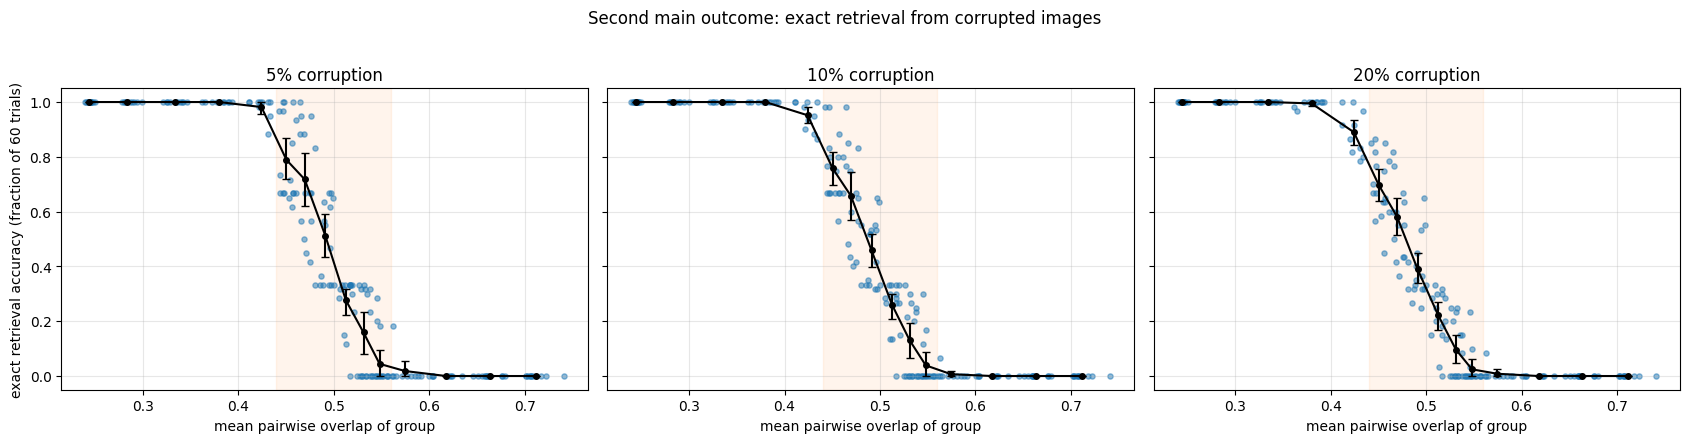

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, c in zip(axes, [5, 10, 20]):
    col = f"acc_{c}"
    bm_c = bin_means_ci(gs, col)
    ax.axvspan(0.44, 0.56, color="tab:orange", alpha=0.08)
    ax.scatter(gs.mean_overlap, gs[col], s=14, alpha=0.5, color="tab:blue")
    ax.errorbar(bin_mid, bm_c[:, 0], yerr=[bm_c[:, 0] - bm_c[:, 1], bm_c[:, 2] - bm_c[:, 0]],
                color="k", marker="o", ms=4, capsize=3)
    ax.set_title(f"{c}% corruption"); ax.set_xlabel("mean pairwise overlap of group")
    ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
axes[0].set_ylabel("exact retrieval accuracy (fraction of 60 trials)")
plt.suptitle("Second main outcome: exact retrieval from corrupted images", y=1.02)
plt.tight_layout()
save_and_show("step5_noisy_retrieval")

## 8. Group-level association and the descriptive logistic curve

**Spearman ρ** between group overlap and each outcome (n = 180 groups), with a bootstrap 95% CI from resampling groups.

**Logistic curve, fitted only when justified.** The fitted curve is
$p(m) = 1 / (1 + e^{\,s\,(m - m_{50})})$, where $m_{50}$ is the overlap at which the outcome is 50%.
It is fitted to **group-level** fractions with equal weight per group, so trials are not treated as independent observations.

It is fitted only if **all** of these hold:
1. **Reasonably monotonic:** the Spearman CI lies entirely below 0, *and* no bin mean rises by more than 0.15 over the previous bin.
2. **Crosses 50% within the data:** at least one bin mean is ≥ 0.5 and at least one is ≤ 0.5.

The estimate of $m_{50}$ is reported as **reliable** only if, in addition, ≥ 90% of bootstrap refits succeed and the bootstrap 95% CI for $m_{50}$ lies **inside the observed overlap range**.
Otherwise the table says why, and no threshold is reported.

In [49]:
def fit_logistic(x, y):
    """Fractional logistic fit (Bernoulli quasi-likelihood, equal weight per group). Returns (m50, s) or None."""
    def nll(p):
        m50, log_s = p
        q = np.clip(expit(-np.exp(log_s) * (x - m50)), 1e-9, 1 - 1e-9)
        return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))
    best = None
    for m0 in np.percentile(x, [25, 50, 75]):
        r = minimize(nll, x0=[m0, np.log(20)], method="Nelder-Mead", options=dict(xatol=1e-6, fatol=1e-9, maxiter=4000))
        if r.success and (best is None or r.fun < best.fun):
            best = r
    if best is None:
        return None
    m50, s = best.x[0], np.exp(best.x[1])
    return (m50, s) if np.isfinite(m50) and s < 1e4 else None

x_all = gs.mean_overlap.values
xmin, xmax = x_all.min(), x_all.max()
log_rng = np.random.default_rng(CONFIG["BOOTSTRAP_SEED"] + 1)
fits, report = {}, []
for col, name in [("stable_frac", "clean stability (primary)"), ("acc_5", "accuracy 5%"),
                  ("acc_10", "accuracy 10%"), ("acc_20", "accuracy 20%")]:
    y = gs[col].values
    rho, lo, hi = spearman_ci(x_all, y)
    means = bin_means_ci(gs, col)[:, 0]
    means = means[~np.isnan(means)]
    max_rise = float(np.max(np.diff(means))) if len(means) > 1 else np.nan
    monotonic = (hi < 0) and (max_rise <= CONFIG["MONOTONIC_MAX_RISE"])
    crosses = (means.max() >= 0.5) and (means.min() <= 0.5)
    row = dict(outcome=name, mean=y.mean(), spearman_rho=rho, rho_ci_low=lo, rho_ci_high=hi,
               max_bin_rise=max_rise, monotonic=monotonic, crosses_50=crosses,
               m50=np.nan, m50_ci_low=np.nan, m50_ci_high=np.nan, slope=np.nan, status="")
    if not monotonic:
        row["status"] = "not fitted: relationship not reasonably monotonic"
    elif not crosses:
        row["status"] = "not fitted: bin means do not cross 50% in observed range"
    else:
        f = fit_logistic(x_all, y)
        if f is None:
            row["status"] = "fit failed"
        else:
            boots = []
            for _ in range(CONFIG["LOGISTIC_BOOTSTRAP_SAMPLES"]):
                i = log_rng.integers(0, len(x_all), len(x_all))
                fb = fit_logistic(x_all[i], y[i])
                if fb is not None:
                    boots.append(fb[0])
            ok_frac = len(boots) / CONFIG["LOGISTIC_BOOTSTRAP_SAMPLES"]
            ci = np.percentile(boots, [2.5, 97.5]) if boots else (np.nan, np.nan)
            row.update(m50=f[0], slope=f[1], m50_ci_low=ci[0], m50_ci_high=ci[1])
            reliable = ok_frac >= 0.9 and xmin <= ci[0] and ci[1] <= xmax
            row["status"] = (f"fitted; m50 reliable (bootstrap success {ok_frac:.0%})" if reliable
                             else f"fitted, but m50 NOT reliable (bootstrap success {ok_frac:.0%}, CI vs range [{xmin:.2f}, {xmax:.2f}])")
            fits[col] = (f, reliable)
    report.append(row)

stats_report = pd.DataFrame(report)
stats_report.to_csv(RESULTS_DIR / "step5_statistics.csv", index=False)
stats_report.round(3)

,outcome,mean,spearman_rho,rho_ci_low,rho_ci_high,max_bin_rise,monotonic,crosses_50,m50,m50_ci_low,m50_ci_high,slope,status
0,clean stability (primary),0.515,-0.928,-0.939,-0.912,0.0,True,True,0.497,0.493,0.502,47.149,fitted; m50 reliable (bootstrap success 100%)
1,accuracy 5%,0.486,-0.950,-0.958,-0.937,0.0,True,True,0.490,0.486,0.494,45.121,fitted; m50 reliable (bootstrap success 100%)
2,accuracy 10%,0.467,-0.959,-0.966,-0.942,0.0,True,True,0.485,0.481,0.488,43.744,fitted; m50 reliable (bootstrap success 100%)
3,accuracy 20%,0.439,-0.960,-0.968,-0.945,0.0,True,True,0.477,0.474,0.480,41.692,fitted; m50 reliable (bootstrap success 100%)


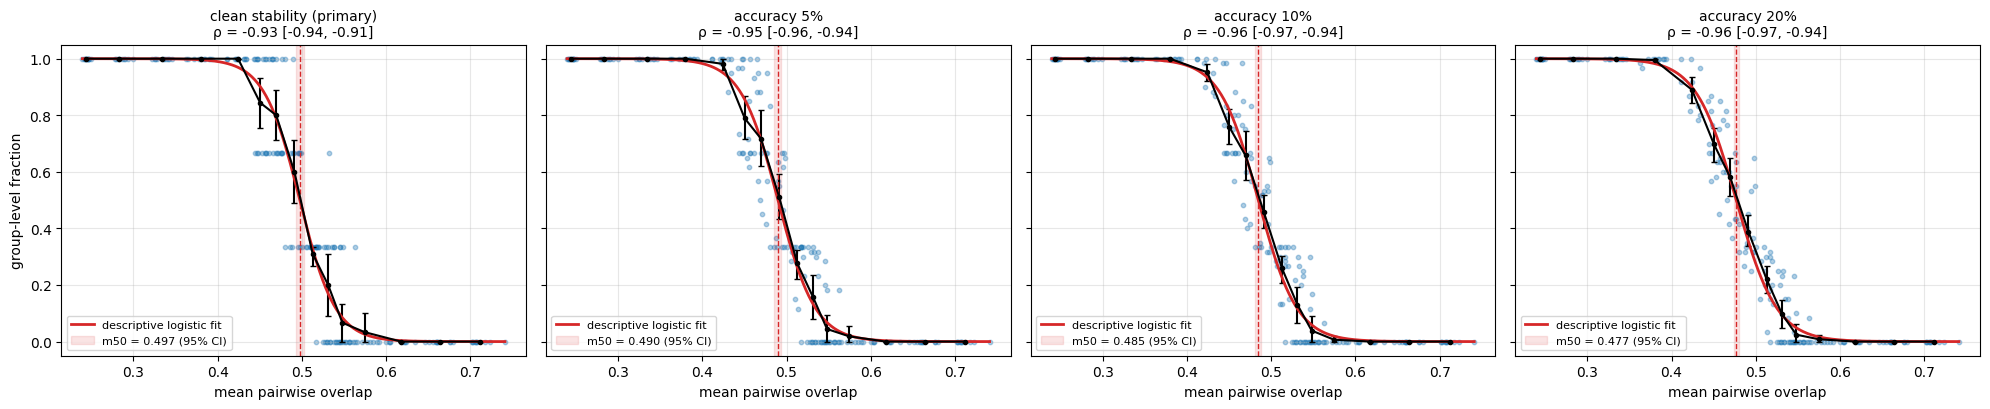

In [50]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), sharey=True)
xs = np.linspace(xmin, xmax, 300)
for ax, (col, name) in zip(axes, [("stable_frac", "clean stability (primary)"), ("acc_5", "accuracy 5%"),
                                  ("acc_10", "accuracy 10%"), ("acc_20", "accuracy 20%")]):
    bmc = bin_means_ci(gs, col)
    ax.scatter(gs.mean_overlap, gs[col], s=10, alpha=0.35, color="tab:blue")
    ax.errorbar(bin_mid, bmc[:, 0], yerr=[bmc[:, 0] - bmc[:, 1], bmc[:, 2] - bmc[:, 0]], color="k", marker="o", ms=3, capsize=2)
    r = stats_report.set_index("outcome").loc[name]
    if col in fits:
        (m50, s), reliable = fits[col]
        ax.plot(xs, expit(-s * (xs - m50)), color="tab:red", lw=2, label="descriptive logistic fit")
        if reliable:
            ax.axvline(m50, color="tab:red", ls="--", lw=1)
            ax.axvspan(r.m50_ci_low, r.m50_ci_high, color="tab:red", alpha=0.12, label=f"m50 = {m50:.3f} (95% CI)")
        ax.legend(fontsize=8, loc="lower left")
    ax.set_title(f"{name}\nρ = {r.spearman_rho:.2f} [{r.rho_ci_low:.2f}, {r.rho_ci_high:.2f}]", fontsize=10)
    ax.set_xlabel("mean pairwise overlap"); ax.grid(alpha=0.3); ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("group-level fraction")
plt.tight_layout()
save_and_show("step5_logistic_fits")

## 9. Final overlap with the target, and shared attractors

The **final overlap** shows how close failed recalls get. It is descriptive, and a high value is **not** retrieval.
**Shared attractors** show whether different stored images end in the *identical* state, i.e. whether the memories have merged.

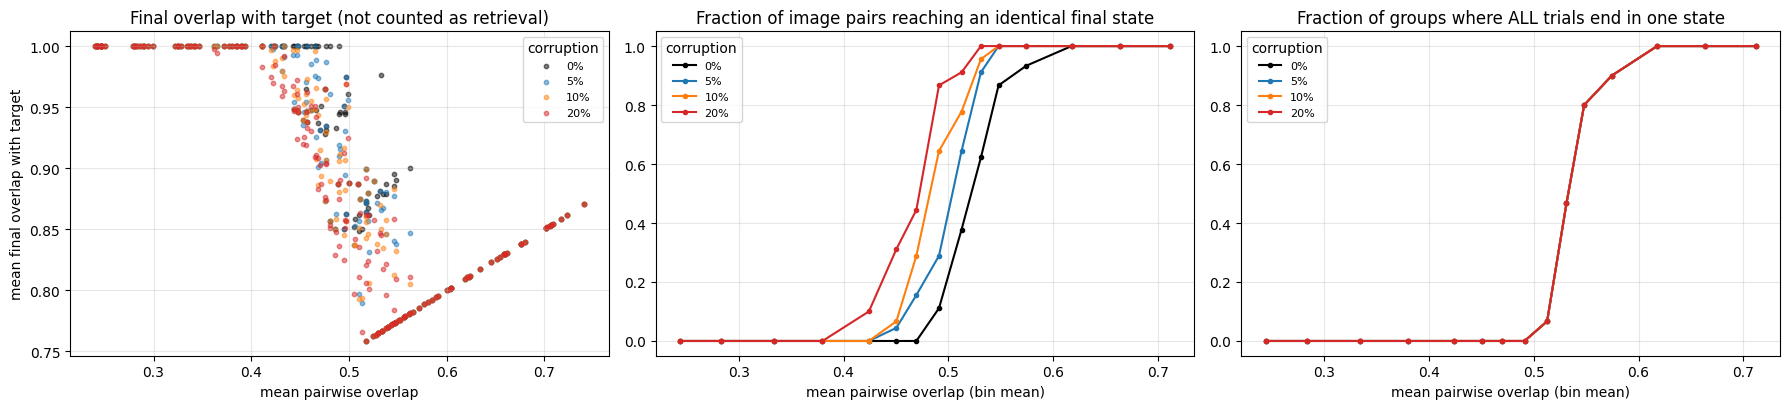

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for c, col in zip([0, 5, 10, 20], ["k", "tab:blue", "tab:orange", "tab:red"]):
    axes[0].scatter(gs.mean_overlap, gs[f"final_overlap_{c}"], s=10, alpha=0.5, color=col, label=f"{c}%")
axes[0].set_xlabel("mean pairwise overlap"); axes[0].set_ylabel("mean final overlap with target")
axes[0].set_title("Final overlap with target (not counted as retrieval)"); axes[0].legend(title="corruption", fontsize=8)

for c, col in zip([0, 5, 10, 20], ["k", "tab:blue", "tab:orange", "tab:red"]):
    bmc = bin_means_ci(gs, f"pairs_shared_{c}")
    axes[1].plot(bin_mid, bmc[:, 0], marker="o", ms=3, color=col, label=f"{c}%")
    bmm = bin_means_ci(gs.assign(m=gs[f"all_merged_{c}"].astype(float)), "m")
    axes[2].plot(bin_mid, bmm[:, 0], marker="o", ms=3, color=col, label=f"{c}%")
axes[1].set_title("Fraction of image pairs reaching an identical final state"); axes[1].set_ylim(-0.05, 1.05)
axes[2].set_title("Fraction of groups where ALL trials end in one state"); axes[2].set_ylim(-0.05, 1.05)
for ax in axes[1:]:
    ax.set_xlabel("mean pairwise overlap (bin mean)"); ax.legend(title="corruption", fontsize=8); ax.grid(alpha=0.3)
axes[0].grid(alpha=0.3)
plt.tight_layout()
save_and_show("step5_final_overlap_and_attractors")

### What is the shared non-memory state?

With 3 stored patterns, classical theory predicts a **symmetric mixture state**: the pixel-by-pixel majority vote
$\operatorname{sign}(\xi^1 + \xi^2 + \xi^3)$. A sum of three ±1 values is never 0, so the majority is always defined.
Its overlap with each stored image, averaged over the three, equals exactly $(1 + \bar m)/2$, where $\bar m$ is the group's mean pairwise overlap.
This would explain the straight line of merged groups in the final-overlap plot.

The cell below checks this **exactly** against the saved final states: is every `other_attractor` trial's final state identical to its group's majority pattern?

In [52]:
oa = trials[trials.outcome == "other_attractor"]
is_majority = np.zeros(len(oa), dtype=bool)
for k, r in enumerate(oa.itertuples()):
    majority = np.sign(patterns[gidx[r.group_id]].sum(axis=0))
    is_majority[k] = np.array_equal(unpack_state(final_states[r.trial_id]), majority)
print(f"other_attractor trials: {len(oa):,}")
print(f"  ending exactly in the majority (mixture) state: {is_majority.sum():,} ({is_majority.mean():.1%})")
print(f"  ending in some other state: {(~is_majority).sum():,}")

# The theoretical overlap of the majority state, averaged over targets, is (1 + mean pairwise overlap) / 2
maj_m = [np.mean([overlap(np.sign(patterns[gidx[g]].sum(0)), patterns[i]) for i in gidx[g]]) for g in gs.index]
assert np.allclose(maj_m, (1 + gs.mean_overlap.values) / 2)
print("check passed: mean overlap of majority state with the stored images = (1 + m̄)/2 for every group")

other_attractor trials: 22,599
  ending exactly in the majority (mixture) state: 22,599 (100.0%)
  ending in some other state: 0
check passed: mean overlap of majority state with the stored images = (1 + m̄)/2 for every group


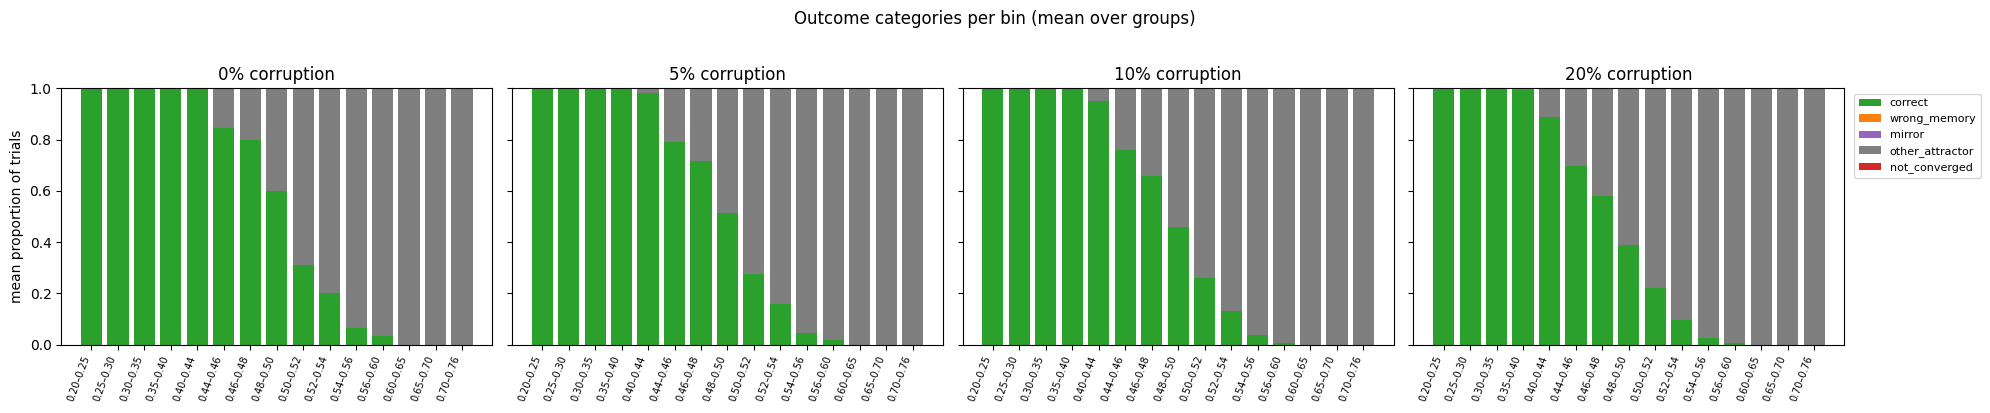

In [53]:
colors = {"correct": "tab:green", "wrong_memory": "tab:orange", "mirror": "tab:purple",
          "other_attractor": "tab:gray", "not_converged": "tab:red"}
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, c in zip(axes, [0, 5, 10, 20]):
    bottom = np.zeros(n_bins)
    for cat in CATEGORIES:
        v = gs.groupby("bin")[f"{cat}_{c}"].mean().reindex(range(n_bins)).fillna(0).values
        ax.bar(range(n_bins), v, bottom=bottom, color=colors[cat], label=cat); bottom += v
    ax.set_xticks(range(n_bins)); ax.set_xticklabels(bin_labels, rotation=70, ha="right", fontsize=7)
    ax.set_title(f"{c}% corruption")
axes[0].set_ylabel("mean proportion of trials"); axes[-1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.suptitle("Outcome categories per bin (mean over groups)", y=1.02)
plt.tight_layout()
save_and_show("step5_outcome_breakdown")

## 10. Sensitivity checks

**(a) Image reuse.** Build a subset of groups in which **no image appears twice**: go through the groups in a seeded random order and keep a group only if none of its images is already kept. Then recompute Spearman ρ.

**(b) Digit composition.** Find the digit whose presence differs most between groups above and below overlap 0.50, drop every group containing it, and recompute Spearman ρ.
That digit is chosen *from the data*, so this is a robustness check, not a test.

In [54]:
sub_rng = np.random.default_rng(CONFIG["SUBSET_SEED"])
kept, seen = [], set()
for gid in sub_rng.permutation(gs.index.values):
    imgs = set(map(int, gs.loc[gid, "images"].split()))
    if not imgs & seen:
        kept.append(gid); seen |= imgs
disjoint = gs.loc[sorted(kept)]

has_digit = np.array([[str(d) in g.split() for d in range(10)] for g in gs.digits])
upper = gs.mean_overlap.values >= 0.50
diff = has_digit[upper].mean(0) - has_digit[~upper].mean(0)
drop_digit = int(np.argmax(np.abs(diff)))
no_digit = gs[~has_digit[:, drop_digit]]
print("digit presence, groups with overlap ≥0.50 minus <0.50:", dict(enumerate(diff.round(2))))
print(f"most imbalanced digit: {drop_digit}")

rows = []
for col, name in [("stable_frac", "clean stability (primary)"), ("acc_5", "accuracy 5%"),
                  ("acc_10", "accuracy 10%"), ("acc_20", "accuracy 20%")]:
    for label, df in [("all groups", gs), ("no reused images", disjoint), (f"without digit {drop_digit}", no_digit)]:
        rho, lo, hi = spearman_ci(df.mean_overlap.values, df[col].values)
        rows.append(dict(outcome=name, subset=label, n_groups=len(df), spearman_rho=rho, ci_low=lo, ci_high=hi))
sens = pd.DataFrame(rows)
sens.to_csv(RESULTS_DIR / "step5_sensitivity.csv", index=False)
sens.round(3)

digit presence, groups with overlap ≥0.50 minus <0.50: {0: -0.07, 1: 0.18, 2: -0.14, 3: 0.25, 4: -0.42, 5: 0.19, 6: -0.1, 7: -0.27, 8: 0.24, 9: 0.14}
most imbalanced digit: 4


,outcome,subset,n_groups,spearman_rho,ci_low,ci_high
0,clean stability (primary),all groups,180,-0.928,-0.940,-0.912
1,clean stability (primary),no reused images,73,-0.923,-0.943,-0.883
2,clean stability (primary),without digit 4,125,-0.905,-0.927,-0.863
3,accuracy 5%,all groups,180,-0.950,-0.958,-0.936
4,accuracy 5%,no reused images,73,-0.938,-0.955,-0.898
5,accuracy 5%,without digit 4,125,-0.921,-0.945,-0.882
6,accuracy 10%,all groups,180,-0.959,-0.966,-0.944
7,accuracy 10%,no reused images,73,-0.945,-0.964,-0.901
8,accuracy 10%,without digit 4,125,-0.924,-0.949,-0.885
9,accuracy 20%,all groups,180,-0.960,-0.968,-0.944


## 11. Supporting evidence (earlier experiments, unchanged)

The headline numbers from the saved step-4 (5 memories) and pilot (2–4 memories) results, side by side with this experiment.
The studies used different sampling designs, so this is context and **not** a pooled analysis.

In [55]:
s4 = pd.read_csv(RESULTS_DIR / "step4_groups.csv")
ctx = [dict(study="pilot k=2 (12 groups)", stable=(pilot[pilot['size']==2].n_stable/2).mean()),
       dict(study="this experiment k=3 (180 groups)", stable=gs.stable_frac.mean()),
       dict(study="pilot k=3 (12 groups)", stable=pilot3.stable_frac.mean()),
       dict(study="pilot k=4 (12 groups)", stable=(pilot[pilot['size']==4].n_stable/4).mean()),
       dict(study="step 4 k=5 (84 groups)", stable=(s4.n_stable/5).mean())]
pd.DataFrame(ctx).rename(columns={"stable": "mean clean stability"}).round(3)

,study,mean clean stability
0,pilot k=2 (12 groups),1.000
1,this experiment k=3 (180 groups),0.515
2,pilot k=3 (12 groups),0.611
3,pilot k=4 (12 groups),0.062
4,step 4 k=5 (84 groups),0.005


## 12. Mechanism validation (saved results only)

This section re-checks the step-5 findings **directly from the saved final states**, then states the underlying mathematics with its assumptions spelled out.
No simulation is re-run, and the Hopfield code and saved results are unchanged.

Every claim is labelled:
- **[Observation]**: measured in this experiment's data
- **[Deduction]**: follows mathematically from the model; the assumptions are stated, then checked against our data
- **[Interpretation]**: a plausible explanation that is not proven

### 12.1 [Observation] Every final state is either the exact target or the exact majority-vote state

The comparison uses the **unpacked saved states**, not the outcome labels.
For each trial: is the state identical to the target image? Is it identical to $M = \operatorname{sign}(\xi^1+\xi^2+\xi^3)$ for that group?

In [56]:
assert np.array_equal(gs.index.values, np.arange(len(gs)))
maj_bits = np.array([patterns[gidx[g]].sum(axis=0) > 0 for g in range(len(gs))])     # majority, as ink bits

is_tgt = np.zeros(len(trials), dtype=bool)
is_maj = np.zeros(len(trials), dtype=bool)
img_idx = trials.image_index.values
grp_idx = trials.group_id.values
for s in range(0, len(trials), 5000):                      # in chunks, to keep memory small
    sl = slice(s, s + 5000)
    bits = np.unpackbits(final_states[sl], axis=1)[:, :N].astype(bool)
    is_tgt[sl] = np.all(bits == (patterns[img_idx[sl]] > 0), axis=1)
    is_maj[sl] = np.all(bits == maj_bits[grp_idx[sl]], axis=1)

assert np.array_equal(is_tgt, (trials.outcome == "correct").values), "labels disagree with saved states"
maj_equals_stored = any(np.array_equal(maj_bits[g], patterns[i] > 0) for g in range(len(gs)) for i in gidx[g])

check = pd.DataFrame({
    "trials": trials.groupby("corruption").size(),
    "exact target": pd.Series(is_tgt).groupby(trials.corruption.values).sum(),
    "exact majority M": pd.Series(is_maj).groupby(trials.corruption.values).sum(),
    "neither": pd.Series(~is_tgt & ~is_maj).groupby(trials.corruption.values).sum(),
    "both": pd.Series(is_tgt & is_maj).groupby(trials.corruption.values).sum(),
})
check.loc["total"] = check.sum()
print("M identical to one of its group's stored images in any group:", maj_equals_stored)
check

M identical to one of its group's stored images in any group: False


,trials,exact target,exact majority M,neither,both
0.0,10800,5560,5240,0,0
0.05,10800,5249,5551,0,0
0.1,10800,5048,5752,0,0
0.2,10800,4744,6056,0,0
total,43200,20601,22599,0,0


### 12.2 [Deduction] Overlap of the majority state with each stored image

**Valid for any three ±1 patterns and any N.** At each pixel the three images either all agree, or one image is the **minority** (the other two share the opposite value).
Let $s_a$ be the fraction of pixels where image $a$ is the minority. Then:
- $M$ differs from $\xi^a$ exactly on $a$'s minority pixels, so $m(M,\xi^a) = 1 - 2s_a$.
- From the pairwise overlaps, $m_{ab} = 1 - 2(s_a + s_b)$, and likewise for the other pairs. Hence $m_{ab}+m_{ac}-m_{bc} = 1 - 4s_a$.

Therefore

$$m(M,\xi^a) = \frac{1 + m_{ab} + m_{ac} - m_{bc}}{2}\quad\text{(single image)},\qquad \frac13\sum_a m(M,\xi^a) = \frac{1+\bar m}{2}\quad\text{(mean over the 3 images)}.$$

The group formula $(1+\bar m)/2$ is **not** the overlap for an individual image or trial. It is exact only for the average over the three images.
For example, it is exact for the group-mean final overlap of a fully merged group, because each image contributes the same number of trials.

In [57]:
mech_rows = []
for g in range(len(gs)):
    I = gidx[g]; Q = patterns[I]; M3 = Q @ Q.T / N
    W = train_hebbian(Q)
    Mg = np.sign(Q.sum(axis=0))
    for a in range(K):
        b, c = [k for k in range(K) if k != a]
        minority = (Q[b] == -Q[a]) & (Q[c] == -Q[a])
        mech_rows.append(dict(
            group_id=g, image_pos=a, image_index=int(I[a]), mean_overlap=gs.loc[g, "mean_overlap"],
            m_ab=M3[a, b], m_ac=M3[a, c], m_bc=M3[b, c], pair_sum=M3[a, b] + M3[a, c],
            n_minority=int(minority.sum()),
            mix_overlap=overlap(Mg, Q[a]),
            mix_overlap_formula=(1 + M3[a, b] + M3[a, c] - M3[b, c]) / 2,
            mix_overlap_group_formula=(1 + gs.loc[g, "mean_overlap"]) / 2,
            stable_observed=bool(is_fixed_point(W, Q[a]) == 1.0),
        ))
mech = pd.DataFrame(mech_rows)

print("per-image formula exact for all", len(mech), "images:", np.allclose(mech.mix_overlap, mech.mix_overlap_formula))
dev = (mech.mix_overlap - mech.mix_overlap_group_formula).abs()
print(f"single image vs (1+m̄)/2: mean |difference| {dev.mean():.3f}, max {dev.max():.3f}")
print("mean over each group's 3 images equals (1+m̄)/2 for all groups:",
      np.allclose(mech.groupby("group_id").mix_overlap.mean(), mech.groupby("group_id").mix_overlap_group_formula.first()))

failed = trials.outcome.values != "correct"
gform = (1 + gs.mean_overlap.values[grp_idx]) / 2
print(f"failed trials vs (1+m̄)/2: mean |difference| {np.abs(trials.final_overlap_target.values[failed] - gform[failed]).mean():.3f}, "
      f"max {np.abs(trials.final_overlap_target.values[failed] - gform[failed]).max():.3f}")

per-image formula exact for all 540 images: True
single image vs (1+m̄)/2: mean |difference| 0.058, max 0.268
mean over each group's 3 images equals (1+m̄)/2 for all groups: True
failed trials vs (1+m̄)/2: mean |difference| 0.049, max 0.188


### 12.3 [Deduction] When is a stored image a fixed point?

**Local field identity (any number P of stored patterns, any N).** With $W_{ij}=\frac1N\sum_\mu \xi^\mu_i\xi^\mu_j$ and $W_{ii}=0$:

$$h_i(s) = \sum_{j\neq i} W_{ij}s_j = \sum_\mu \xi^\mu_i\, m_\mu(s) - \frac{P}{N}s_i.$$

**At a stored image, with 3 patterns.** Put $s=\xi^a$, so $m_a = 1$, $m_b = m_{ab}$ and $m_c = m_{ac}$. Write $\sigma_b = \xi^a_i\xi^b_i$ and $\sigma_c = \xi^a_i\xi^c_i$ (+1 if that image agrees with $a$ at pixel $i$, −1 if not). Then

$$\xi^a_i h_i = 1 - \tfrac{3}{N} + \sigma_b\, m_{ab} + \sigma_c\, m_{ac}.$$

There are only 4 pixel types: (agree, agree), (agree, opposite), (opposite, agree) and the **minority** type (opposite, opposite).

**Proposition 1** (exact; any three distinct ±1 patterns, any N; update rule *sign(h), keep the state if h = 0*):
$\xi^a$ is a fixed point **if and only if** $1 - 3/N + \sigma_b m_{ab} + \sigma_c m_{ac} \ge 0$ **for every pixel type that actually occurs**.
(Equality counts as stable, because a neuron with $h_i = 0$ keeps its state.)

**Corollary (the simplified rule), only under these assumptions:**
- **A1.** Image $a$ has at least one minority pixel.
- **A2.** $|m_{ab} - m_{ac}| < 1 - 3/N$, so the two mixed pixel types are always stable.
- **A3.** $m_{ab} + m_{ac} > -(1 - 3/N)$, so the (agree, agree) type is always stable.

Then $\xi^a$ is a fixed point $\iff m_{ab} + m_{ac} \le 1 - 3/N$.

**Ties (A4).** $N\,m_{ab}$ always has the same parity as N, because $N m = N - 2d$ with d the number of differing pixels.
So for **even N**, $N\,\xi^a_i h_i = N - 3 \pm N m_{ab} \pm N m_{ac}$ is **odd** and can never be 0. Equality is impossible, and "≤" and "<" give the same result.
For odd N, ties *can* occur, and the rule keeps the state.

**The simplified rule is not a general theorem.** Without A1–A3 it can be wrong in both directions. The next cell builds two small synthetic counterexamples (N = 16) and checks them with the unchanged `train_hebbian` and `is_fixed_point`.

In [58]:
def simplified_rule(Q, a):
    """The corollary's prediction: stable iff m_ab + m_ac <= 1 - 3/N."""
    n = Q.shape[1]
    b, c = [k for k in range(3) if k != a]
    return (Q[a] @ Q[b] + Q[a] @ Q[c]) / n <= 1 - 3 / n

n_toy = 16
toy_rng = np.random.default_rng(7)
xa = toy_rng.choice([-1.0, 1.0], n_toy)

# Counterexample 1 (violates A2): b is almost a, c is almost -a, and at pixel 0 b disagrees with a while c agrees.
xb1 = xa.copy(); xb1[0] *= -1
xc1 = -xa.copy(); xc1[[0, 1]] *= -1
# Counterexample 2 (violates A1): b and c each differ from a at different pixels, so a has no minority pixel.
xb2 = xa.copy(); xb2[[0, 1, 2]] *= -1
xc2 = xa.copy(); xc2[[3, 4, 5]] *= -1

for name, Q in [("counterexample 1 (A2 violated)", np.array([xa, xb1, xc1])),
                ("counterexample 2 (A1 violated)", np.array([xa, xb2, xc2]))]:
    M3 = Q @ Q.T / n_toy
    actual = is_fixed_point(train_hebbian(Q), Q[0]) == 1.0
    print(f"{name}: m_ab={M3[0,1]:+.3f}, m_ac={M3[0,2]:+.3f}, sum={M3[0,1]+M3[0,2]:+.3f}, 1-3/N={1-3/n_toy:.3f} | "
          f"simplified rule says stable: {simplified_rule(Q, 0)} | actually stable: {actual}")

counterexample 1 (A2 violated): m_ab=+0.875, m_ac=-0.750, sum=+0.125, 1-3/N=0.812 | simplified rule says stable: True | actually stable: False
counterexample 2 (A1 violated): m_ab=+0.625, m_ac=+0.625, sum=+1.250, 1-3/N=0.812 | simplified rule says stable: False | actually stable: True


Now check the assumptions and the rule on **our 540 stored images**.
The parity check also confirms directly that $N\,\xi^a_i h_i$ is an odd integer at every pixel, so no ties can occur.

In [59]:
assump = []
for r in mech.itertuples():
    Q = patterns[gidx[r.group_id]]
    W = train_hebbian(Q)
    v = N * Q[r.image_pos] * (W @ Q[r.image_pos])          # N * xi_i * h_i at every pixel
    v_int = np.round(v)
    assump.append(dict(integer=np.allclose(v, v_int), odd=np.all(v_int % 2 == 1), min_abs=np.abs(v_int).min()))
assump = pd.DataFrame(assump)

mech["A1_has_minority"] = mech.n_minority >= 1
mech["A2_ok"] = (mech.m_ab - mech.m_ac).abs() < 1 - 3 / N
mech["A3_ok"] = mech.pair_sum > -(1 - 3 / N)
mech["rule_predicts_stable"] = mech.pair_sum <= 1 - 3 / N
mech["margin"] = 1 - 3 / N - mech.pair_sum                # >0 stable, <0 unstable (under A1-A3)

print(f"A1  minority pixels: min {mech.n_minority.min()}, median {int(mech.n_minority.median())}  -> holds for {mech.A1_has_minority.sum()}/{len(mech)}")
print(f"A2  max |m_ab - m_ac| = {(mech.m_ab - mech.m_ac).abs().max():.3f} < {1 - 3/N:.4f}  -> holds for {mech.A2_ok.sum()}/{len(mech)}")
print(f"A3  min (m_ab + m_ac) = {mech.pair_sum.min():.3f} > {-(1 - 3/N):.4f}  -> holds for {mech.A3_ok.sum()}/{len(mech)}")
print(f"A4  N = {N} (even); N*xi*h integer everywhere: {assump.integer.all()}, odd everywhere: {assump.odd.all()}, "
      f"smallest |N*xi*h| = {int(assump.min_abs.min())} (so h is never 0)")
print(f"rule vs observed fixed-point status: {(mech.rule_predicts_stable == mech.stable_observed).sum()}/{len(mech)} agree")
closest = mech.loc[mech.margin.abs().idxmin()]
print(f"closest image to the boundary: margin = {closest.margin:+.5f} = {closest.margin * N:+.0f}/N "
      f"(group {int(closest.group_id)}, stable: {closest.stable_observed})")
mech.to_csv(RESULTS_DIR / "step5_mechanism_checks.csv", index=False)

A1  minority pixels: min 37, median 126  -> holds for 540/540
A2  max |m_ab - m_ac| = 0.430 < 0.9971  -> holds for 540/540
A3  min (m_ab + m_ac) = 0.225 > -0.9971  -> holds for 540/540
A4  N = 1024 (even); N*xi*h integer everywhere: True, odd everywhere: True, smallest |N*xi*h| = 1 (so h is never 0)
rule vs observed fixed-point status: 540/540 agree
closest image to the boundary: margin = -0.00098 = -1/N (group 64, stable: False)


### 12.4 [Deduction] Why an unstable image slides exactly into the mixture state

**Proposition 2.** Suppose (i) $\xi^a$ is stable on all its non-minority pixels (guaranteed by A2 and A3), (ii) $M$ is a fixed point, and (iii) $\xi^a$ is unstable.
Then asynchronous recall started at $\xi^a$ ends **exactly at $M$, for any update order**.

*Why.* Every minority pixel $j$ of $a$ has the same pattern values: $\xi^a_j = -x$ and $\xi^b_j = \xi^c_j = x = M_j$.
So flipping $j$ from $\xi^a_j$ to $M_j$ changes the field of every other neuron $i$ by the **same** amount, $\Delta h_i = \tfrac{2}{N}(\xi^b_i + \xi^c_i - \xi^a_i)$, whichever $j$ it is.
Every neuron's field is therefore a straight-line function of *how many* minority pixels have flipped, between its value at $\xi^a$ and its value at $M$ (a neuron's own state never enters its own field, since $W_{ii}=0$).
- A non-minority pixel has the correct sign at both ends, by (i) and (ii), so it never flips.
- A not-yet-flipped minority pixel points toward $M_i$ at both ends, by (iii) and (ii), so it always flips eventually.

The dynamics stop only when every minority pixel has flipped, and that state is exactly $M$.

**When is M a fixed point?** For any three patterns, $M_i h_i(M)$ takes two forms:
- on pixels where all three agree: $(3 + m_{ab} + m_{ac} + m_{bc})/2 - 3/N$
- on pixels where image $a$ is the minority: $(1 - m_{ab} - m_{ac} + 3m_{bc})/2 - 3/N$

For three *uncorrelated* patterns this is about 1/2 > 0, the classical result that 3-mixtures are spurious attractors. The cell checks it on our groups.

*Scope:* this is proved for **clean** starts only. That corrupted starts also end at $M$ is an **observation** (section 12.1), not a deduction.

In [60]:
mix_rows = []
for g in range(len(gs)):
    Q = patterns[gidx[g]]; W = train_hebbian(Q); M3 = Q @ Q.T / N
    Mg = np.sign(Q.sum(axis=0))
    margin_obs = Mg * (W @ Mg)
    # predicted margin for each pixel type
    pred = np.empty(N)
    agree = (Q[0] == Q[1]) & (Q[1] == Q[2])
    pred[agree] = (3 + M3[0, 1] + M3[0, 2] + M3[1, 2]) / 2 - 3 / N
    for a in range(3):
        b, c = [k for k in range(3) if k != a]
        mino = (Q[b] == -Q[a]) & (Q[c] == -Q[a])
        pred[mino] = (1 - M3[a, b] - M3[a, c] + 3 * M3[b, c]) / 2 - 3 / N
    mix_rows.append(dict(group_id=g, M_fixed_point=bool(np.all(margin_obs > 0)),
                         formula_exact=np.allclose(margin_obs, pred), min_margin=margin_obs.min()))
mix = pd.DataFrame(mix_rows)
print(f"M is a fixed point in {mix.M_fixed_point.sum()}/{len(mix)} groups; margin formula exact in {mix.formula_exact.sum()}/{len(mix)}; "
      f"smallest margin {mix.min_margin.min():.3f}")

# Check the constant-increment step on one group
g = int(mech.loc[~mech.stable_observed, "group_id"].iloc[0]); a = int(mech.loc[(mech.group_id == g) & ~mech.stable_observed, "image_pos"].iloc[0])
Q = patterns[gidx[g]]; W = train_hebbian(Q); b, c = [k for k in range(3) if k != a]
mino = np.where((Q[b] == -Q[a]) & (Q[c] == -Q[a]))[0]
expected = 2 / N * (Q[b] + Q[c] - Q[a])
ok = all(np.allclose(np.delete(W[:, j] * (2 * Q[b][j]), j), np.delete(expected, j)) for j in mino[:20])
print(f"flipping any minority pixel changes every other field by the same vector (group {g}, image {a}): {ok}")

# Conditions (i)-(iii) for every unstable image, plus the predicted outcome of clean recall
unst = mech[~mech.stable_observed]
cond_i = unst.A2_ok & unst.A3_ok
cond_ii = mix.set_index("group_id").loc[unst.group_id, "M_fixed_point"].values
print(f"unstable images: {len(unst)}; conditions (i) hold: {cond_i.sum()}, (ii) hold: {cond_ii.sum()}")
clean_fail = trials[(trials.corruption == 0) & (trials.outcome != "correct")]
print(f"[Observation] clean-start trials of unstable images ending exactly at M: {is_maj[clean_fail.index].sum()}/{len(clean_fail)} "
      f"(Proposition 2 predicts all of them)")

M is a fixed point in 180/180 groups; margin formula exact in 180/180; smallest margin 0.267
flipping any minority pixel changes every other field by the same vector (group 52, image 0): True
unstable images: 262; conditions (i) hold: 262, (ii) hold: 262
[Observation] clean-start trials of unstable images ending exactly at M: 5240/5240 (Proposition 2 predicts all of them)


### 12.5 [Observation] Stable images with small margins are the ones that fail under corruption

For each stable image, the margin $1 - 3/N - (m_{ab}+m_{ac})$ is the slack in Proposition 1. The table gives the image-level exact retrieval accuracy (20 trials per level).
**[Interpretation]** Corruption weakens the pull back toward the target and adds random variation to every neuron's input. Images with little slack can be pushed into the mixture's basin, so the 50% point moves to lower group overlap as corruption increases. This is not derived.

In [61]:
acc_img = (trials.assign(ok=is_tgt)
           .pivot_table(index=["group_id", "image_pos"], columns="corruption", values="ok", aggfunc="mean"))
acc_img.columns = [f"acc_{int(c*100)}" for c in acc_img.columns]
mech = mech.merge(acc_img.reset_index(), on=["group_id", "image_pos"])

st = mech[mech.stable_observed].copy()
st["margin_bin"] = pd.cut(st.margin, [0, 0.05, 0.10, 0.15, 0.20, 0.30, 1.0])
tab = st.groupby("margin_bin", observed=True)[["acc_5", "acc_10", "acc_20"]].mean().round(3)
tab.insert(0, "images", st.groupby("margin_bin", observed=True).size())
print("unstable images, mean accuracy at 0/5/10/20%:",
      mech.loc[~mech.stable_observed, ["acc_0", "acc_5", "acc_10", "acc_20"]].mean().round(3).to_dict())
mech.to_csv(RESULTS_DIR / "step5_mechanism_checks.csv", index=False)
tab

unstable images, mean accuracy at 0/5/10/20%: {'acc_0': 0.0, 'acc_5': 0.0, 'acc_10': 0.0, 'acc_20': 0.0}


,images,acc_5,acc_10,acc_20
margin_bin,,,,
"(0.0, 0.05]",60,0.744,0.594,0.433
"(0.05, 0.1]",35,0.994,0.964,0.834
"(0.1, 0.15]",28,1.000,1.000,0.966
"(0.15, 0.2]",33,1.000,1.000,0.998
"(0.2, 0.3]",40,1.000,1.000,1.000
"(0.3, 1.0]",82,1.000,1.000,1.000


### 12.6 Summary of claims

| claim | type | assumptions | checked on our data |
|---|---|---|---|
| Every final state is exactly the target or exactly $M$ | Observation | none | 43,200 / 43,200 trials (12.1) |
| $m(M,\xi^a) = (1+m_{ab}+m_{ac}-m_{bc})/2$; group mean $= (1+\bar m)/2$ | Deduction | any three ±1 patterns | 540 / 540 images, 180 / 180 groups (12.2) |
| Fixed point $\iff$ every occurring pixel type has $1-3/N+\sigma_b m_{ab}+\sigma_c m_{ac} \ge 0$ | Deduction | any three distinct patterns | used for the check in 12.3 |
| Fixed point $\iff m_{ab}+m_{ac} < 1-3/N$ | Deduction (corollary) | A1–A3, N even | A1–A4 hold for 540 / 540 images, and the rule matches 540 / 540; it fails for the synthetic counterexamples |
| M is a fixed point | Observation, with an exact condition | the margin formula | 180 / 180 groups (12.4) |
| An unstable image's clean recall ends exactly at M | Deduction | (i)–(iii) | conditions hold for every unstable image; observed in every clean failure |
| Corrupted failures also end at M | Observation only | none | all failures at 5–20% |
| Small margin explains failures under corruption | Interpretation, supported by 12.5 | none | none (not derived) |

## 13. How much of the overlap is shared background?

The similarity measure stays **exactly** as defined: the bipolar overlap $m$. This section only splits it into parts.

For two 0/1 images, every pixel is one of three kinds:
- $p_{00}$: fraction of pixels where **both are background** (white)
- $p_{11}$: fraction where **both are ink**
- $p_{\mathrm{dis}}$: fraction where they **disagree**

**[Deduction]** Since $m = \frac1N\sum_i \xi_i\eta_i$ and every agreeing pixel contributes +1 and every disagreeing pixel −1:

$$m = p_{00} + p_{11} - p_{\mathrm{dis}} = 1 - 2\,p_{\mathrm{dis}}.$$

So the bipolar overlap gives **shared background exactly the same weight as shared ink**. It depends only on how many pixels differ.

We also separate out **border pixels**: pixels that are ink in fewer than 5% of the 476 typical images. Agreement there carries almost no information about which digit is drawn.

Each group's value is the mean over its 3 pairs, and bins are averages over groups, so the group stays the unit of analysis.

In [62]:
imgs01 = images.reshape(len(images), N).astype(np.float64)
pool_ink_prob = imgs01[pool].mean(axis=0)
border = pool_ink_prob < 0.05
print(f"border pixels (ink in <5% of typical images): {border.sum()} of {N}; never ink: {(pool_ink_prob == 0).sum()}")

pair_rows = []
for g in range(len(gs)):
    for a, b in combinations(gidx[g], 2):
        x, z = imgs01[a], imgs01[b]
        both_bg = (1 - x) * (1 - z)
        pair_rows.append(dict(
            group_id=g, bin=gs.loc[g, "bin"], img_a=int(a), img_b=int(b), m=overlap(patterns[a], patterns[b]),
            p00=both_bg.mean(), p00_border=(both_bg * border).mean(), p00_central=(both_bg * ~border).mean(),
            p11=(x * z).mean(), p_dis=(x != z).mean(),
            ink_a=x.mean(), ink_b=z.mean(),
            ink_jaccard=(x * z).sum() / np.maximum(((x + z) > 0).sum(), 1),   # shared ink / ink in either image
        ))
pairs = pd.DataFrame(pair_rows)
assert np.allclose(pairs.m, pairs.p00 + pairs.p11 - pairs.p_dis)        # the decomposition is exact
assert np.allclose(pairs.m, 1 - 2 * pairs.p_dis)
pairs.to_csv(RESULTS_DIR / "step5_overlap_decomposition.csv", index=False)

grp = pairs.groupby("group_id").mean(numeric_only=True)
grp["ink"] = (grp.ink_a + grp.ink_b) / 2
decomp = grp.groupby("bin")[["m", "p00_border", "p00_central", "p11", "p_dis", "ink", "ink_jaccard"]].mean()
decomp.index = [bin_labels[int(b)] for b in decomp.index]
decomp["background share of agreement"] = (decomp.p00_border + decomp.p00_central) / (decomp.p00_border + decomp.p00_central + decomp.p11)
decomp.round(3)

border pixels (ink in <5% of typical images): 372 of 1024; never ink: 241


,m,p00_border,p00_central,p11,p_dis,ink,ink_jaccard,background share of agreement
0.20–0.25,0.244,0.343,0.158,0.121,0.378,0.310,0.246,0.805
0.25–0.30,0.283,0.347,0.164,0.131,0.358,0.310,0.270,0.795
0.30–0.35,0.334,0.352,0.178,0.136,0.333,0.303,0.291,0.796
0.35–0.40,0.380,0.357,0.177,0.156,0.310,0.311,0.337,0.774
0.40–0.44,0.424,0.360,0.186,0.166,0.288,0.310,0.366,0.767
0.44–0.46,0.450,0.360,0.197,0.168,0.275,0.305,0.380,0.769
0.46–0.48,0.470,0.360,0.204,0.171,0.265,0.304,0.392,0.767
0.48–0.50,0.491,0.361,0.205,0.180,0.254,0.307,0.415,0.759
0.50–0.52,0.513,0.361,0.202,0.194,0.244,0.315,0.444,0.744
0.52–0.54,0.531,0.363,0.213,0.189,0.234,0.307,0.448,0.752


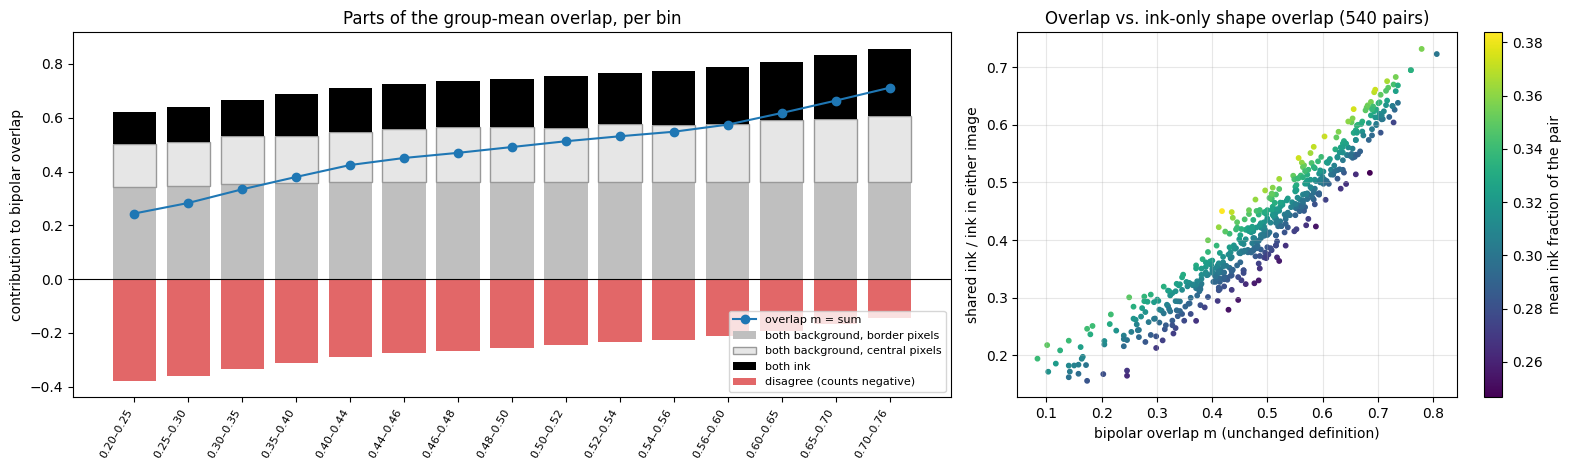

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(len(decomp))
ax = axes[0]
ax.bar(x, decomp.p00_border, color="0.75", label="both background, border pixels")
ax.bar(x, decomp.p00_central, bottom=decomp.p00_border, color="0.9", edgecolor="0.6", label="both background, central pixels")
ax.bar(x, decomp.p11, bottom=decomp.p00_border + decomp.p00_central, color="k", label="both ink")
ax.bar(x, -decomp.p_dis, color="tab:red", alpha=0.7, label="disagree (counts negative)")
ax.plot(x, decomp.m, "o-", color="tab:blue", label="overlap m = sum")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(decomp.index, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("contribution to bipolar overlap"); ax.set_title("Parts of the group-mean overlap, per bin")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
sc = ax.scatter(pairs.m, pairs.ink_jaccard, c=(pairs.ink_a + pairs.ink_b) / 2, cmap="viridis", s=10)
plt.colorbar(sc, ax=ax, label="mean ink fraction of the pair")
ax.set_xlabel("bipolar overlap m (unchanged definition)"); ax.set_ylabel("shared ink / ink in either image")
ax.set_title("Overlap vs. ink-only shape overlap (540 pairs)")
ax.grid(alpha=0.3)
plt.tight_layout()
save_and_show("step5_overlap_decomposition")

In [64]:
rho_ink = spearmanr(grp.m, grp.ink).statistic
rho_jac = spearmanr(pairs.m, pairs.ink_jaccard).statistic
rand_m = ((1 - pairs.ink_a) * (1 - pairs.ink_b) + pairs.ink_a * pairs.ink_b
          - (pairs.ink_a * (1 - pairs.ink_b) + (1 - pairs.ink_a) * pairs.ink_b))
lo, hi = decomp.iloc[0], decomp.iloc[-1]
print(f"[Observation] border-pixel background adds {decomp.p00_border.min():.3f}-{decomp.p00_border.max():.3f} to every overlap (almost constant)")
print(f"[Observation] lowest to highest bin, m rises by {hi.m - lo.m:+.3f}: "
      f"border bg {hi.p00_border - lo.p00_border:+.3f}, central bg {hi.p00_central - lo.p00_central:+.3f}, "
      f"shared ink {hi.p11 - lo.p11:+.3f}, fewer disagreements {-(hi.p_dis - lo.p_dis):+.3f}")
print(f"[Observation] group-level Spearman: overlap vs mean ink fraction rho = {rho_ink:.2f}")
print(f"[Observation] pair-level Spearman: overlap vs ink-only shape overlap rho = {rho_jac:.3f}")
print(f"[Observation] mean overlap if each image's ink were scattered randomly (same ink amount): {rand_m.mean():.3f} "
      f"vs observed {pairs.m.mean():.3f}")

[Observation] border-pixel background adds 0.343-0.363 to every overlap (almost constant)
[Observation] lowest to highest bin, m rises by +0.468: border bg +0.020, central bg +0.084, shared ink +0.130, fewer disagreements +0.234
[Observation] group-level Spearman: overlap vs mean ink fraction rho = 0.18
[Observation] pair-level Spearman: overlap vs ink-only shape overlap rho = 0.965
[Observation] mean overlap if each image's ink were scattered randomly (same ink amount): 0.143 vs observed 0.485


### 13.1 The stability rule in pixel counts, and the limit set by the background

**[Deduction]** With $m = 1 - 2d/N$, where $d$ is the number of pixels at which two images differ, the step-12.3 rule $m_{ab}+m_{ac} < 1 - 3/N$ becomes

$$d_{ab} + d_{ac} > \frac{N+3}{2} = 513.5\quad\Longleftrightarrow\quad d_{ab}+d_{ac} \ge 514.$$

In words: a stored image survives only if it differs, **in total**, from the other two images on more than half the pixels.

Two images can differ only on pixels where at least one of them has ink, so $d_{ab} \le \text{ink}_a + \text{ink}_b$. With about 31% ink, two typical digits can differ on at most about 630 pixels, and in practice on far fewer.
The large shared background is therefore what makes the 514-pixel requirement hard to meet.

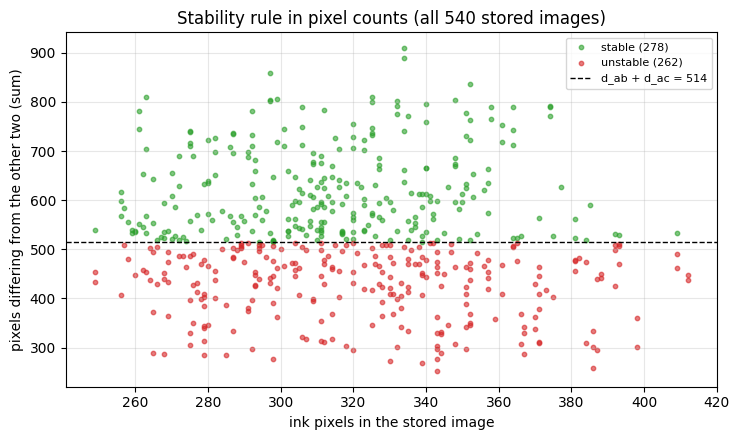

d_ab + d_ac: median 518, range 253-909; Spearman(ink pixels, d_sum) = -0.10


In [65]:
mech["d_sum"] = np.round((1 - mech.m_ab) * N / 2 + (1 - mech.m_ac) * N / 2).astype(int)
assert np.array_equal(mech.d_sum >= 514, mech.rule_predicts_stable)
ink_count = imgs01.sum(axis=1)
mech["ink_pixels"] = ink_count[mech.image_index.values]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for stable, col, lab in [(True, "tab:green", "stable"), (False, "tab:red", "unstable")]:
    s = mech[mech.stable_observed == stable]
    ax.scatter(s.ink_pixels, s.d_sum, s=10, alpha=0.6, color=col, label=f"{lab} ({len(s)})")
ax.axhline(514, color="k", ls="--", lw=1, label="d_ab + d_ac = 514")
ax.set_xlabel("ink pixels in the stored image"); ax.set_ylabel("pixels differing from the other two (sum)")
ax.set_title("Stability rule in pixel counts (all 540 stored images)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
save_and_show("step5_hamming_stability")
print(f"d_ab + d_ac: median {int(mech.d_sum.median())}, range {mech.d_sum.min()}-{mech.d_sum.max()}; "
      f"Spearman(ink pixels, d_sum) = {spearmanr(mech.ink_pixels, mech.d_sum).statistic:.2f}")
mech.to_csv(RESULTS_DIR / "step5_mechanism_checks.csv", index=False)

### 13.2 What the background means for "similarity"

- **[Observation]** Agreement on border pixels, which are almost always blank, adds a nearly constant ≈0.35 to **every** pair's overlap, in every bin.
  The digit drawn has almost no effect on this part of the overlap. It sets the *level* of similarity: all digit pairs look strongly correlated to the network.
- **[Observation]** The *differences* in overlap between bins come from less disagreement in the drawing region: more shared ink and more shared central background.
  Ink amount barely changes across bins. Overlap ranks pairs almost exactly like the ink-only shape overlap (ρ shown above).
  So, **within this dataset, the ordering of groups by overlap reflects digit-shape similarity, not differences in how much ink an image has**.
- **[Deduction]** The network's limit is set in *raw* overlap (equivalently, in the 514-pixel count), and shared background uses up much of that budget.
  So *where* the transition happens (m̄ ≈ 0.5) is a joint property of digit shape **and** of the large shared background in this ±1 coding.
  It is **not** a statement about digit-shape similarity alone.
- **[Interpretation]** Describe the result as "memories with higher raw pixel overlap interfere more". Avoid "digits that look more alike interfere more", unless it is made clear that the absolute threshold includes shared background.
  A coding or learning rule that discounts shared background would probably move the transition, but this project deliberately does not test that (the learning rule stays unchanged).

## 14. Saved outputs

| file | contents |
|---|---|
| `step5_config.json` | all settings and seeds |
| `step5_sampling_report.csv` | candidates, target, sampled, shortfall, cap skips, digit TVD per bin |
| `step5_groups.csv` | one row per group: images, digits, overlap, bin, clean stability |
| `step5_trials.csv` | one row per trial, with `trial_id` |
| `step5_final_states.npy` | uint8 array (n_trials × 128): bit-packed final states, row = `trial_id` |
| `step5_group_summary.csv` | group-level outcomes: stability, accuracy, final overlap, attractor sharing, categories |
| `step5_statistics.csv` | Spearman ρ, monotonicity check, logistic fit status and m50 |
| `step5_sensitivity.csv` | reuse and digit sensitivity checks |
| `step5_mechanism_checks.csv` | per stored image: overlaps, minority pixels, stability rule vs. observed, margin, accuracy, pixel-count form (section 12) |
| `step5_overlap_decomposition.csv` | per image pair: shared background (border/central), shared ink, disagreement (section 13) |
| `figures/step5_*.png` | all plots |

To read a final state: `unpack_state(np.load("results/step5_final_states.npy")[trial_id])`.

Interpretation and the human-memory comparison come in later steps.